In [1]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# Data Import (& Export)

We gaan een aantal manieren oefenen waarmee je data kunt inlezen:<br>
- CSV-bestanden<br>
- Excel-bestanden<br>
- Web-scraping



# CSV-bestanden (hoofdstuk 7)
We gebruiken een simpel csv-bestand als voorbeeld: students.<br>
Om dit bestand in te lezen in deze Colab, moet je het eerst in de content-map uploaden.

In [ ]:
students <- read_csv("students.csv")
students

Rows: 6 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): Full Name, favourite.food, mealPlan, AGE
dbl (1): Student ID

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,N/A,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


We kunnen ook de link naar het csv-bestand op internet vinden:<br>
https://raw.githubusercontent.com/hadley/r4ds/main/data/students.csv,<br>
en het vervolgens inlezen:

In [ ]:
csv_url <- "https://raw.githubusercontent.com/hadley/r4ds/main/data/students.csv"

csv_data <- read.csv(csv_url)
#csv_data <- read.csv("https://raw.githubusercontent.com/hadley/r4ds/main/data/students.csv")
head(csv_data)

,Student.ID,Full.Name,favourite.food,mealPlan,AGE
,<int>,<chr>,<chr>,<chr>,<chr>
1,1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,2,Barclay Lynn,French fries,Lunch only,5
3,3,Jayendra Lyne,N/A,Breakfast and lunch,7
4,4,Leon Rossini,Anchovies,Lunch only,
5,5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,6,Güvenç Attila,Ice cream,Lunch only,6


# Intermezzo: Tibbles
We maken van de ingelezen csv-file een [tibble](https://tibble.tidyverse.org/):

In [ ]:
students <- as_tibble(students)
students

Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,N/A,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


Er staat een vervelende N/A in de favourite.food kolom, die willen we vervangen door een echte NA:

In [ ]:
students <- read_csv("students.csv", na = c("N/A", ""))
students

Rows: 6 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): Full Name, favourite.food, mealPlan, AGE
dbl (1): Student ID

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


De namen van de eerste 2 kolommen (Student ID en Full Name) bevatten spaties. Dat willen we niet, dus hernoemen we deze kolommen. Let Op dat je de oude kolomnamen (met spaties) tussen 'backticks' (`) zet:

In [ ]:
students <- rename(students, student_id = `Student ID`, full_name = `Full Name`)

In [ ]:
students

student_id,full_name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


We willen geen hoofdletters in de kolomnamen. Met een apart commando (clean_names) gaan we dat oplossen. Daarvoor moeten we wel eerst het 'janitor'-pakket installeren:

In [ ]:
install.packages("janitor")
library(janitor)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
students <- students |> janitor::clean_names()
students

student_id,full_name,favourite_food,meal_plan,age
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


De kolom leeftijd zou alleen uit getallen moeten bestaan, maar er staat 'five' in plaats van 5 in regel 5. Dat gaan we aanpassen:

In [ ]:
students <- mutate(students, age = ifelse(age == "five", 5, as.numeric(age)))

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `age = ifelse(age == "five", 5, as.numeric(age))`.
Caused by warning in `ifelse()`:
! NAs introduced by coercion”


In [ ]:
students

student_id,full_name,favourite_food,meal_plan,age
<dbl>,<chr>,<chr>,<chr>,<dbl>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,5
6,Güvenç Attila,Ice cream,Lunch only,6


We gaan rekenen met de waarden uit de kolom 'age', die slaan we dus op in een aparte variabele genaamd 'leeftijd':

In [ ]:
leeftijd <- students$age
leeftijd

[1]  4  5  7 NA  5  6

We willen de gemiddelde leeftijd berekenen:

In [ ]:
mean(leeftijd)

[1] NA

Ai, daar hebben we de NA's weer: eerst verwijderen ..

In [ ]:
leeftijd_zonder_NA <- na.omit(leeftijd)
mean(leeftijd_zonder_NA)

[1] 5.4

Of alle NA's vullen:

In [ ]:
install.packages("zoo")
library(zoo)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
leeftijd_NA_gevuld <- na.locf(leeftijd)
mean(leeftijd_NA_gevuld)

[1] 5.666667

Kunnen we dit bestand nu ook weer opslaan als een csv-file?<br>
Natuurlijk:

In [ ]:
write.csv(leeftijd_zonder_NA, "leeftijd.csv")


# Excel-bestanden (hoofdstuk 20)
We kunnen ook Excel-bestanden inlezen (en weer opslaan):

In [ ]:
install.packages(c("readxl","writexl"))
library(readxl)
library(writexl)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
students <- read_excel("students.xlsx", sheet = "Sheet1")
head(students)

Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4.0
2,Barclay Lynn,French fries,Lunch only,5.0
3,Jayendra Lyne,N/A,Breakfast and lunch,7.0
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6.0


Eerst maar weer de kolomnamen aanpassen:

In [ ]:
students <- read_excel(
  "students.xlsx",
  col_names = c("student_id", "full_name", "favourite_food", "meal_plan", "age")
)
students

student_id,full_name,favourite_food,meal_plan,age
<chr>,<chr>,<chr>,<chr>,<chr>
Student ID,Full Name,favourite.food,mealPlan,AGE
1.0,Sunil Huffmann,Strawberry yoghurt,Lunch only,4.0
2.0,Barclay Lynn,French fries,Lunch only,5.0
3.0,Jayendra Lyne,N/A,Breakfast and lunch,7.0
4.0,Leon Rossini,Anchovies,Lunch only,NA
5.0,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6.0,Güvenç Attila,Ice cream,Lunch only,6.0


Ai, dat gaat niet goed: we hebben nu de kolomnamen toegevoed als eerste regel aan onze data.<br>Dat is niet de bedoeling, dus we passen het aan:

In [ ]:
students <- read_excel(
  "students.xlsx",
  col_names = c("student_id", "full_name", "favourite_food", "meal_plan", "age"),
  skip = 1
)
students

student_id,full_name,favourite_food,meal_plan,age
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4.0
2,Barclay Lynn,French fries,Lunch only,5.0
3,Jayendra Lyne,N/A,Breakfast and lunch,7.0
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6.0


De N/A willen we ook hier vervangen:

In [ ]:
students <- read_excel(
  "students.xlsx",
  col_names = c("student_id", "full_name", "favourite_food", "meal_plan", "age"),
  skip = 1,
  na = c("", "N/A")
)
students

student_id,full_name,favourite_food,meal_plan,age
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4.0
2,Barclay Lynn,French fries,Lunch only,5.0
3,Jayendra Lyne,NA,Breakfast and lunch,7.0
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6.0


En het probleem met de 'five' moeten we ook hier oplossen.<br>
We kunnen per kolom aangeven wat het datatype is:

In [ ]:
students <- read_excel(
  "students.xlsx",
  col_names = c("student_id", "full_name", "favourite_food", "meal_plan", "age"),
  skip = 1,
  na = c("", "N/A"),
  col_types = c("numeric", "text", "text", "text", "numeric")
)
students

Warning message:
“Expecting numeric in E6 / R6C5: got 'five'”


student_id,full_name,favourite_food,meal_plan,age
<dbl>,<chr>,<chr>,<chr>,<dbl>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,NA
6,Güvenç Attila,Ice cream,Lunch only,6


Dit gaat niet helemaal goed: de 'five' op regel 5 is nu vervangen door een NA. Beter is om eerst ook de 'age' kolom als text in te lezen, en vervolgens de 'five' te vervangen met een 5:

In [ ]:
students <- read_excel(
  "students.xlsx",
  col_names = c("student_id", "full_name", "favourite_food", "meal_plan", "age"),
  skip = 1,
  na = c("", "N/A"),
  col_types = c("numeric", "text", "text", "text", "text")
)

In [ ]:
students <- mutate(students, age = ifelse(age == "five", 5, as.numeric(age)))

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `age = ifelse(age == "five", 5, as.numeric(age))`.
Caused by warning in `ifelse()`:
! NAs introduced by coercion”


In [ ]:
students

student_id,full_name,favourite_food,meal_plan,age
<dbl>,<chr>,<chr>,<chr>,<dbl>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,5
6,Güvenç Attila,Ice cream,Lunch only,6


Vooruit, 1 grafiekje:

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_count()`).”


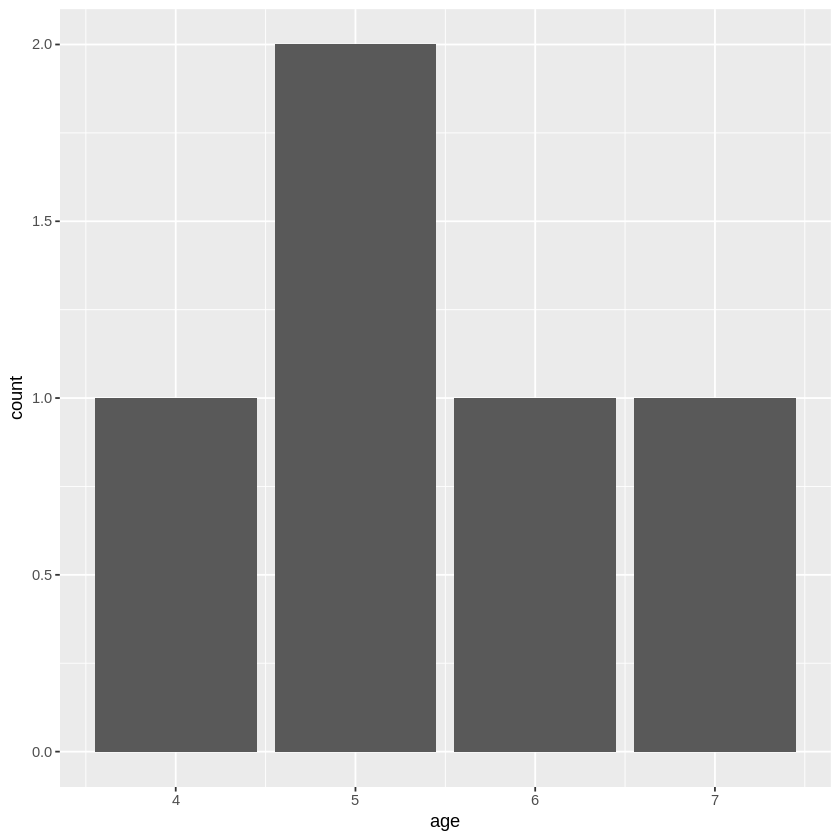

In [ ]:
ggplot(data = students) +
  geom_bar(mapping = aes(x = age))

Je kunt in ieder geval ook dit Excel-bestand weer opslaan:

In [ ]:
write_xlsx(students, "opgeslagenstudentenbestand.xlsx")

## Kun je ook een gedeelte van een Excel-sheet inlezen?
Ja, dat kan. We gebruiken een voorbeeldbestand van readxl met daarin beroemde doden:

In [ ]:
deaths_path <- readxl_example("deaths.xlsx")
deaths <- read_excel(deaths_path)

New names:
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`


In [ ]:
deaths

Lots of people,...2,...3,...4,...5,...6
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
simply cannot resist writing,NA,NA,NA,NA,some notes
at,the,top,NA,of,their spreadsheets
or,merging,NA,NA,NA,cells
Name,Profession,Age,Has kids,Date of birth,Date of death
David Bowie,musician,69,TRUE,17175,42379
Carrie Fisher,actor,60,TRUE,20749,42731
Chuck Berry,musician,90,TRUE,9788,42812
Bill Paxton,actor,61,TRUE,20226,42791
Prince,musician,57,TRUE,21343,42481


De eerste 4 regels en de laatste 4 regels hebben we niet nodig. De data die we zoeken zit in de cellen A5 tot en met F15:

In [ ]:
read_excel(deaths_path, range = "A5:F15")

Name,Profession,Age,Has kids,Date of birth,Date of death
<chr>,<chr>,<dbl>,<lgl>,<dttm>,<dttm>
David Bowie,musician,69,TRUE,1947-01-08,2016-01-10
Carrie Fisher,actor,60,TRUE,1956-10-21,2016-12-27
Chuck Berry,musician,90,TRUE,1926-10-18,2017-03-18
Bill Paxton,actor,61,TRUE,1955-05-17,2017-02-25
Prince,musician,57,TRUE,1958-06-07,2016-04-21
Alan Rickman,actor,69,FALSE,1946-02-21,2016-01-14
Florence Henderson,actor,82,TRUE,1934-02-14,2016-11-24
Harper Lee,author,89,FALSE,1926-04-28,2016-02-19
Zsa Zsa Gábor,actor,99,TRUE,1917-02-06,2016-12-18


# Intermezzo: lezen en opslaan met R of R Studio
Let Op: als je in plaats van de Colab R of R Studio gebruikt, moet je je csv- en/of Excel-bestand in de juiste map zetten om deze te laten inlezen:<br>
- de Documents-folder op je pc

Als je een bestand opslaat, komt het bestand ook in die map terecht.<br>

Als je bestanden in een andere map staan:<br>
- excel_data <- read_excel("Mapnaam\\naam_van_excelbestand.xlsx") of
- excel_data <- read_excel("Mapnaam1\\Mapnaam2\\naam_van_excelbestand.xlsx")


# Web-scraping (hoofdstuk 24)
We gaan web-scrapen met R. Eerst lezen we de benodigde library (rvest) in:

In [3]:
library(rvest)


Attaching package: ‘rvest’


The following object is masked from ‘package:readr’:

    guess_encoding




Vervolgens lezen we de pagina (url) in waarvan we de data gaan 'scrapen':

In [ ]:
url <- "https://rvest.tidyverse.org/articles/starwars.html"
html <- read_html(url)

Op de pagina staan 7 StarWars-films beschreven. We lezen deze in met behulp van het html-element commando 'section':

In [ ]:
section <- html_elements(html, "section")
section

{xml_nodeset (7)}
[1] <section><h2 data-id="1">\nThe Phantom Menace\n</h2>\n<p>\nReleased: 1999 ...
[2] <section><h2 data-id="2">\nAttack of the Clones\n</h2>\n<p>\nReleased: 20 ...
[3] <section><h2 data-id="3">\nRevenge of the Sith\n</h2>\n<p>\nReleased: 200 ...
[4] <section><h2 data-id="4">\nA New Hope\n</h2>\n<p>\nReleased: 1977-05-25\n ...
[5] <section><h2 data-id="5">\nThe Empire Strikes Back\n</h2>\n<p>\nReleased: ...
[6] <section><h2 data-id="6">\nReturn of the Jedi\n</h2>\n<p>\nReleased: 1983 ...
[7] <section><h2 data-id="7">\nThe Force Awakens\n</h2>\n<p>\nReleased: 2015- ...

Nu gaan we uit het 'sectie' gedeelte de afzonderlijke onderdelen inlezen.<br>
We beginnen met de titel, die staat tussen de header-tags (h2). Met het commando 'html_text2' houden we alleen de tekst over:

In [ ]:
section_title <- html_element(section, "h2")
section_title <- html_text2(section_title)
section_title

[1] "The Phantom Menace"      "Attack of the Clones"   
[3] "Revenge of the Sith"     "A New Hope"             
[5] "The Empire Strikes Back" "Return of the Jedi"     
[7] "The Force Awakens"

Zelfde acties, nu voor de regisseur (director):

In [ ]:
section_director <- html_element(section, ".director")
section_director <- html_text2(section_director)
section_director

[1] "George Lucas"     "George Lucas"     "George Lucas"     "George Lucas"    
[5] "Irvin Kershner"   "Richard Marquand" "J. J. Abrams"

Zelfde acties, nu voor de release-datum. We doen hier 2 extra stappen:<br>
<ul><li>we verwijderen de tekst 'Released: ' bij de datum en</li><li>zetten de datum als datum-veld.</li></ul>

In [ ]:
section_released <- html_element(section, "p")
section_released <- html_text2(section_released)
section_released <- str_remove(section_released, "Released: ")
section_released <- parse_date(section_released)
section_released

[1] "1999-05-19" "2002-05-16" "2005-05-19" "1977-05-25" "1980-05-17"
[6] "1983-05-25" "2015-12-11"

Zelfde acties, nu voor de korte omschrijvingen van de inhoud van de films:

In [ ]:
section_intro <- html_element(section, ".crawl")
section_intro <- html_text2(section_intro)
section_intro

[1] "Turmoil has engulfed the Galactic Republic. The taxation of trade routes to outlying star systems is in dispute.\n\nHoping to resolve the matter with a blockade of deadly battleships, the greedy Trade Federation has stopped all shipping to the small planet of Naboo.\n\nWhile the Congress of the Republic endlessly debates this alarming chain of events, the Supreme Chancellor has secretly dispatched two Jedi Knights, the guardians of peace and justice in the galaxy, to settle the conflict…."           
[2] "There is unrest in the Galactic Senate. Several thousand solar systems have declared their intentions to leave the Republic.\n\nThis separatist movement, under the leadership of the mysterious Count Dooku, has made it difficult for the limited number of Jedi Knights to maintain peace and order in the galaxy.\n\nSenator Amidala, the former Queen of Naboo, is returning to the Galactic Senate to vote on the critical issue of creating an ARMY OF THE REPUBLIC to assist the overwhelmed Jedi…."             
[3] "War! The Republic is crumbling under attacks by the ruthless Sith Lord, Count Dooku. There are heroes on both sides. Evil is everywhere.\n\nIn a stunning move, the fiendish droid leader, General Grievous, has swept into the Republic capital and kidnapped Chancellor Palpatine, leader of the Galactic Senate.\n\nAs the Separatist Droid Army attempts to flee the besieged capital with their valuable hostage, two Jedi Knights lead a desperate mission to rescue the captive Chancellor…."                     
[4] "It is a period of civil war. Rebel spaceships, striking from a hidden base, have won their first victory against the evil Galactic Empire.\n\nDuring the battle, Rebel spies managed to steal secret plans to the Empire’s ultimate weapon, the DEATH STAR, an armored space station with enough power to destroy an entire planet.\n\nPursued by the Empire’s sinister agents, Princess Leia races home aboard her starship, custodian of the stolen plans that can save her people and restore freedom to the galaxy…."
[5] "It is a dark time for the Rebellion. Although the Death Star has been destroyed, Imperial troops have driven the Rebel forces from their hidden base and pursued them across the galaxy.\n\nEvading the dreaded Imperial Starfleet, a group of freedom fighters led by Luke Skywalker has established a new secret base on the remote ice world of Hoth.\n\nThe evil lord Darth Vader, obsessed with finding young Skywalker, has dispatched thousands of remote probes into the far reaches of space…."                 
[6] "Luke Skywalker has returned to his home planet of Tatooine in an attempt to rescue his friend Han Solo from the clutches of the vile gangster Jabba the Hutt.\n\nLittle does Luke know that the GALACTIC EMPIRE has secretly begun construction on a new armored space station even more powerful than the first dreaded Death Star.\n\nWhen completed, this ultimate weapon will spell certain doom for the small band of rebels struggling to restore freedom to the galaxy…"                                          
[7] "Luke Skywalker has vanished. In his absence, the sinister FIRST ORDER has risen from the ashes of the Empire and will not rest until Skywalker, the last Jedi, has been destroyed. With the support of the REPUBLIC, General Leia Organa leads a brave RESISTANCE. She is desperate to find her brother Luke and gain his help in restoring peace and justice to the galaxy. Leia has sent her most daring pilot on a secret mission to Jakku, where an old ally has discovered a clue to Luke’s whereabouts…."

We maken van bovenstaande losse bestanden 1 tabel:

In [ ]:
tibble(
  title = section_title,
  released = section_released,
  director = section_director,
  intro = section_intro
)

title,released,director,intro
<chr>,<date>,<chr>,<chr>
The Phantom Menace,1999-05-19,George Lucas,"Turmoil has engulfed the Galactic Republic. The taxation of trade routes to outlying star systems is in dispute. Hoping to resolve the matter with a blockade of deadly battleships, the greedy Trade Federation has stopped all shipping to the small planet of Naboo. While the Congress of the Republic endlessly debates this alarming chain of events, the Supreme Chancellor has secretly dispatched two Jedi Knights, the guardians of peace and justice in the galaxy, to settle the conflict…."
Attack of the Clones,2002-05-16,George Lucas,"There is unrest in the Galactic Senate. Several thousand solar systems have declared their intentions to leave the Republic. This separatist movement, under the leadership of the mysterious Count Dooku, has made it difficult for the limited number of Jedi Knights to maintain peace and order in the galaxy. Senator Amidala, the former Queen of Naboo, is returning to the Galactic Senate to vote on the critical issue of creating an ARMY OF THE REPUBLIC to assist the overwhelmed Jedi…."
Revenge of the Sith,2005-05-19,George Lucas,"War! The Republic is crumbling under attacks by the ruthless Sith Lord, Count Dooku. There are heroes on both sides. Evil is everywhere. In a stunning move, the fiendish droid leader, General Grievous, has swept into the Republic capital and kidnapped Chancellor Palpatine, leader of the Galactic Senate. As the Separatist Droid Army attempts to flee the besieged capital with their valuable hostage, two Jedi Knights lead a desperate mission to rescue the captive Chancellor…."
A New Hope,1977-05-25,George Lucas,"It is a period of civil war. Rebel spaceships, striking from a hidden base, have won their first victory against the evil Galactic Empire. During the battle, Rebel spies managed to steal secret plans to the Empire’s ultimate weapon, the DEATH STAR, an armored space station with enough power to destroy an entire planet. Pursued by the Empire’s sinister agents, Princess Leia races home aboard her starship, custodian of the stolen plans that can save her people and restore freedom to the galaxy…."
The Empire Strikes Back,1980-05-17,Irvin Kershner,"It is a dark time for the Rebellion. Although the Death Star has been destroyed, Imperial troops have driven the Rebel forces from their hidden base and pursued them across the galaxy. Evading the dreaded Imperial Starfleet, a group of freedom fighters led by Luke Skywalker has established a new secret base on the remote ice world of Hoth. The evil lord Darth Vader, obsessed with finding young Skywalker, has dispatched thousands of remote probes into the far reaches of space…."
Return of the Jedi,1983-05-25,Richard Marquand,"Luke Skywalker has returned to his home planet of Tatooine in an attempt to rescue his friend Han Solo from the clutches of the vile gangster Jabba the Hutt. Little does Luke know that the GALACTIC EMPIRE has secretly begun construction on a new armored space station even more powerful than the first dreaded Death Star. When completed, this ultimate weapon will spell certain doom for the small band of rebels struggling to restore freedom to the galaxy…"
The Force Awakens,2015-12-11,J. J. Abrams,"Luke Skywalker has vanished. In his absence, the sinister FIRST ORDER has risen from the ashes of the Empire and will not rest until Skywalker, the last Jedi, has been destroyed. With the support of the REPUBLIC, General Leia Organa leads a brave RESISTANCE. She is desperate to find her brother Luke and gain his help in restoring peace and justice to the galaxy. Leia has sent her most daring pilot on a secret mission to Jakku, where an old ally has discovered a clue to Luke’s whereabouts…."


Website gescraped!

# Huiswerk
Kijk of je de top 250 films van de huidige (dynamische) IMDb-website (https://www.imdb.com/chart/top/?ref_=nv_mv_250) in een mooie tabel kunt scrapen.

In [ ]:
url_nieuw <- "https://www.imdb.com/chart/top/?ref_=nv_mv_250"
html <- read_html(url_nieuw)

In [ ]:
html

Met de oude (statische) website werkte het prima:

In [ ]:
url_oud <- "https://web.archive.org/web/20220201012049/https://www.imdb.com/chart/top/"
html <- read_html(url_oud)
#> # A tibble: 250 × 5
#>   ``    `Rank & Title`                    `IMDb Rating` `Your Rating`   ``
#>   <lgl> <chr>                                     <dbl> <chr>           <lgl>
#> 1 NA    "1.\n      The Shawshank Redempt…           9.2 "12345678910\n… NA
#> 2 NA    "2.\n      The Godfather\n      …           9.1 "12345678910\n… NA
#> 3 NA    "3.\n      The Godfather: Part I…           9   "12345678910\n… NA
#> 4 NA    "4.\n      The Dark Knight\n    …           9   "12345678910\n… NA
#> 5 NA    "5.\n      12 Angry Men\n       …           8.9 "12345678910\n… NA
#> 6 NA    "6.\n      Schindler's List\n   …           8.9 "12345678910\n… NA
#> # ℹ 244 more rows

In [ ]:
table <- html_element(html, "table")
table <- html_table(table)
table

Var.1,Rank & Title,IMDb Rating,Your Rating,Var.5
<lgl>,<chr>,<dbl>,<chr>,<lgl>
NA,1. The Shawshank Redemption (1994),9.2,12345678910 NOT YET RELEASED Seen,NA
NA,2. The Godfather (1972),9.1,12345678910 NOT YET RELEASED Seen,NA
NA,3. The Godfather: Part II (1974),9.0,12345678910 NOT YET RELEASED Seen,NA
NA,4. The Dark Knight (2008),9.0,12345678910 NOT YET RELEASED Seen,NA
NA,5. 12 Angry Men (1957),8.9,12345678910 NOT YET RELEASED Seen,NA
NA,6. Schindler's List (1993),8.9,12345678910 NOT YET RELEASED Seen,NA
NA,7. The Lord of the Rings: The Return of the King (2003),8.9,12345678910 NOT YET RELEASED Seen,NA
NA,8. Pulp Fiction (1994),8.8,12345678910 NOT YET RELEASED Seen,NA
NA,"9. The Good, the Bad and the Ugly (1966)",8.8,12345678910 NOT YET RELEASED Seen,NA


In [ ]:
ratings <- select(table, rank_title_year = `Rank & Title`, rating = `IMDb Rating`)
ratings <- mutate(ratings, rank_title_year = str_replace_all(rank_title_year, "\n +", " "))
ratings <- separate_wider_regex(ratings, rank_title_year, patterns = c(rank = "\\d+", "\\. ", title = ".+", " +\\(", year = "\\d+", "\\)"))
ratings

rank,title,year,rating
<chr>,<chr>,<chr>,<dbl>
1,The Shawshank Redemption,1994,9.2
2,The Godfather,1972,9.1
3,The Godfather: Part II,1974,9.0
4,The Dark Knight,2008,9.0
5,12 Angry Men,1957,8.9
6,Schindler's List,1993,8.9
7,The Lord of the Rings: The Return of the King,2003,8.9
8,Pulp Fiction,1994,8.8
9,"The Good, the Bad and the Ugly",1966,8.8


Succes met de nieuwe ... !